In [99]:
import pandas as pd

In [100]:
!wget "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

--2026-10-19 18:57:34--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv.3’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.03s   

2026-10-19 18:57:34 (8.82 MB/s) - ‘course_lead_scoring_2026.csv.3’ saved [278746/278746]



In [101]:
df = pd.read_csv("course_lead_scoring_2026.csv")

In [102]:
df.dtypes

,0
lead_source,object
industry,object
employment_status,object
location,object
annual_income,float64
number_of_courses_viewed,int64
interaction_count,int64
lead_score,float64
converted,int64


In [103]:
cat=['lead_source','industry','employment_status','location']
num=['annual_income', 'number_of_courses_viewed','interaction_count', 'lead_score']
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [104]:
df[cat] = df[cat].fillna('NA')
df[num] = df[num].fillna('0.0')

In [105]:
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
y_train = df_train.converted.values
y_val = df_val.converted.values

In [106]:
from sklearn.metrics import roc_auc_score

In [107]:
scores = []
for col in num:
  auc = roc_auc_score(y_train, df_train[col])
  if auc < 0.5:
    auc = roc_auc_score(y_train, -df_train[col])
  scores.append((col, auc))

In [108]:
scores

[('annual_income', np.float64(0.6081977776250831)),
 ('number_of_courses_viewed', np.float64(0.7229894623989618)),
 ('interaction_count', np.float64(0.7649203047563227)),
 ('lead_score', np.float64(0.7882254810906102))]

In [109]:
from sklearn.feature_extraction import DictVectorizer

In [110]:
train_dict = df_train[cat + num].to_dict(orient='records')
val_dict= df_val[cat + num].to_dict(orient='records')
dv = DictVectorizer()
x_train = dv.fit_transform(train_dict)
x_val = dv.transform(val_dict)

In [111]:
from sklearn.linear_model import LogisticRegression

In [112]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

In [113]:
model.fit(x_train, y_train)
y_pred = model.predict_proba(x_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)

In [114]:
auc.round(3)

np.float64(0.731)

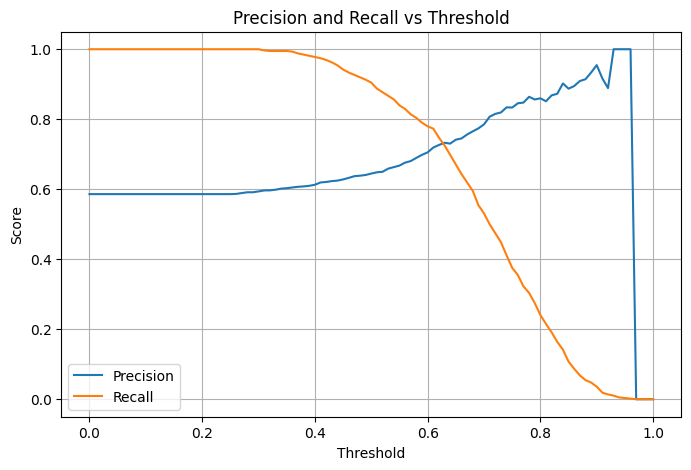

Intersection Threshold: 0.63


In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

thresholds = np.linspace(0, 1, 101)

scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0

    scores.append((t, p, r))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])

plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid()
plt.show()

df_valid = df_scores[(df_scores.precision > 0) & (df_scores.recall > 0)].copy()
df_valid['diff'] = np.abs(df_valid.precision - df_valid.recall)

best_threshold = df_valid.loc[df_valid['diff'].idxmin()]['threshold']
print(f"Intersection Threshold: {best_threshold:.2f}")

In [127]:
import numpy as np
import pandas as pd

thresholds = np.linspace(0, 1, 101)
scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)


    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0


    f1 = (2 * p * r) / (p + r) if (p + r) > 0 else 0

    scores.append((t,p,r, f1))


    df_scores2 = pd.DataFrame(scores, columns=['threshold','precision','recall' ,'f1'])


best_row = df_scores2.loc[df_scores2['f1'].idxmax()]
best_row['threshold']



np.float64(0.41000000000000003)

In [144]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
  df_train = df_full_train.iloc[train_idx]
  df_val = df_full_train.iloc[val_idx]
  x_train = dv.fit_transform(df_train[cat + num].to_dict(orient='records'))
  x_val = dv.transform(df_val[cat + num].to_dict(orient='records'))
  y_train = df_train.converted.values
  y_val = df_val.converted.values


  model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
  model.fit(x_train, y_train)

  y_pred = model.predict_proba(x_val)[:, 1]
  auc = roc_auc_score(y_val, y_pred)
  scores.append(auc)

scores, np.std(scores)

([np.float64(0.7311571176376184),
  np.float64(0.7290516458173177),
  np.float64(0.7372760271856658),
  np.float64(0.7410985247797393),
  np.float64(0.7205779764365441)],
 np.float64(0.007075942270949419))

In [149]:

n_splits = 5
c_values = [0.000001, 0.001, 1]

for C in c_values:
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        x_train = dv.fit_transform(df_train[cat + num].to_dict(orient='records'))
        x_val = dv.transform(df_val[cat + num].to_dict(orient='records'))

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(x_train, y_train)

        y_pred = model.predict_proba(x_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)
    print(C  , mean_auc,std_auc)


1e-06 0.5153214138073584 0.052264896043512254
0.001 0.5391316143034312 0.0981787291528951
1 0.5368863683340223 0.09377650374593902
